In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

### Problem 1
Read an image and apply a custom convolution kernel to sharpen the image.

1. Define a 3x3 sharpening kernel using NumPy and apply it using `cv2.filter2D`. Use the given Laplacian kernel:
```
 0 -1  0
-1  5 -1
 0 -1  0
```
2. Display the original and filtered images side by side using `np.hstack()`

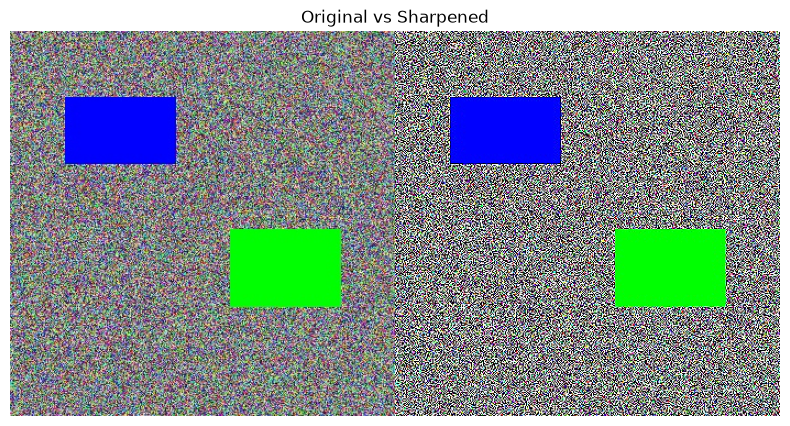

In [3]:
# Create dummy color image 
dummy_color = np.random.randint(0, 256, (350, 350, 3), dtype=np.uint8)
cv2.rectangle(dummy_color, (50, 60), (150, 120), (255, 0, 0), -1)
cv2.rectangle(dummy_color, (200, 180), (300, 250), (0, 255, 0), -1)
cv2.imwrite("dummy_color.jpg", dummy_color)

img_color = cv2.imread('dummy_color.jpg')
if img_color is not None:
    # Define sharpening kernel
    kernel_sharpen = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ])
    
    # Apply filter2D
    img_sharpened = cv2.filter2D(img_color, -1, kernel_sharpen)
    
    # Display side by side using hstack
    combined = np.hstack((img_color, img_sharpened))
    
    # Convert BGR to RGB for matplotlib
    combined_rgb = cv2.cvtColor(combined, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 5))
    plt.title("Original vs Sharpened")
    plt.imshow(combined_rgb)
    plt.axis('off')
    plt.show()


3. Similarly, use 2 Sobel filters of size 3x3 kernel for horizontal and vertical edge detection and display them in 2 different images.

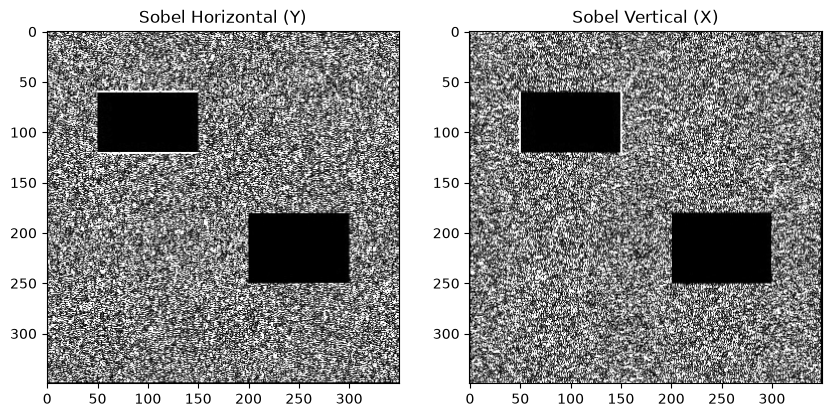

In [4]:
if img_color is not None:
    # Convert to grayscale for edge detection
    gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
 
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_y = cv2.convertScaleAbs(sobel_y)

    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_x = cv2.convertScaleAbs(sobel_x)
    
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title("Sobel Horizontal (Y)")
    plt.imshow(sobel_y, cmap='gray')
    
    plt.subplot(1, 2, 2)
    plt.title("Sobel Vertical (X)")
    plt.imshow(sobel_x, cmap='gray')
    plt.show()


### Problem 2
Work with histogram equalization to enhance image contrast.
1. Load a grayscale image and display its histogram using matplotlib.

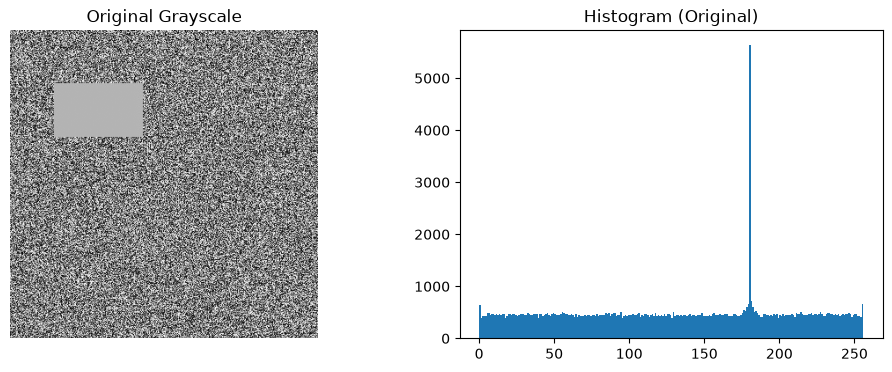

In [6]:
# Create dummy grey image 
dummy_grey = np.random.randint(0, 256, (350, 350), dtype=np.uint8)
cv2.rectangle(dummy_grey, (50, 60), (150, 120), 180, -1)
cv2.imwrite("dummy_grey.jpg", dummy_grey)

img_gray = cv2.imread('dummy_grey.jpg', cv2.IMREAD_GRAYSCALE)

if img_gray is not None:
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.title("Original Grayscale")
    plt.imshow(img_gray, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.title("Histogram (Original)")
    plt.hist(img_gray.ravel(), bins=256, range=[0, 256])
    plt.show()


2. Apply histogram equalization using `cv2.equalizeHist()` and display the result.
3. Plot the histogram of the equalized image and compare it to the original.

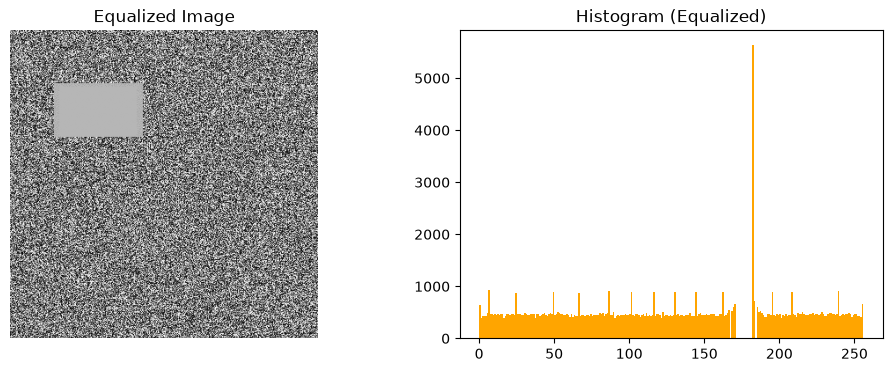

In [7]:
if img_gray is not None:
    img_eq = cv2.equalizeHist(img_gray)
    
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.title("Equalized Image")
    plt.imshow(img_eq, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.title("Histogram (Equalized)")
    plt.hist(img_eq.ravel(), bins=256, range=[0, 256], color='orange')
    plt.show()


### Problem 3
Create a basic image processing pipeline using OpenCV.
1. Load a color image and convert it to grayscale.
2. Apply a Gaussian blur (kernel size 5x5) to reduce noise.
3. Run Canny edge detection and display all three: original, blurred, and edge image side by side using matplotlib.

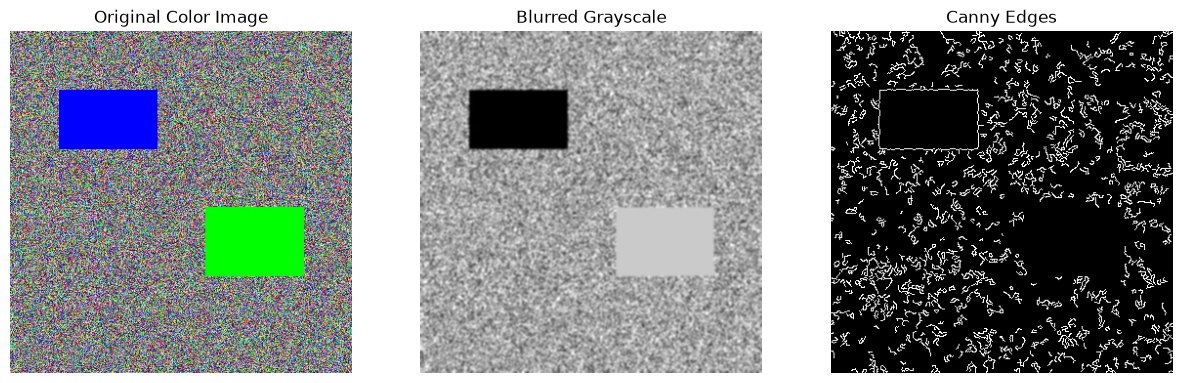

In [8]:
img_color = cv2.imread('dummy_color.jpg')

if img_color is not None:
    # 1. Convert to grayscale
    gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    
    # 2. Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # 3. Canny Edge Detection
    edges = cv2.Canny(blurred, 100, 200)
    
    plt.figure(figsize=(15, 5))
    
    # Display Original 
    plt.subplot(1, 3, 1)
    plt.title("Original Color Image")
    plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    
    # Display Blurred Grayscale
    plt.subplot(1, 3, 2)
    plt.title("Blurred Grayscale")
    plt.imshow(blurred, cmap='gray')
    plt.axis('off')
    
    # Display Edges
    plt.subplot(1, 3, 3)
    plt.title("Canny Edges")
    plt.imshow(edges, cmap='gray')
    plt.axis('off')
    
    plt.show()


### Problem 4
1. Read an image and convert it to grayscale format. Count how many pixels have a brightness greater than a certain threshold (>200). Highlight these bright pixels by drawing white dots at their positions on the image.

Number of pixels with brightness > 200: 8070


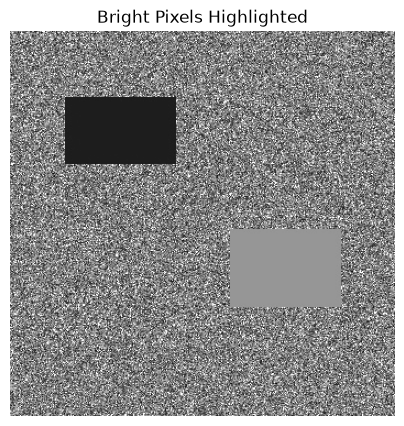

In [9]:
img_color = cv2.imread('dummy_color.jpg')

if img_color is not None:
    # Convert to grayscale
    gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    
    # Find pixels > 200
    bright_pixels = (gray > 200)
    count_bright = np.sum(bright_pixels)
    print(f"Number of pixels with brightness > 200: {count_bright}")
    
    # Highlight with white dots
    highlighted = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    highlighted[bright_pixels] = [255, 255, 255]
    
    plt.figure(figsize=(5, 5))
    plt.title("Bright Pixels Highlighted")
    plt.imshow(cv2.cvtColor(highlighted, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()


2. Read an image in colored format and
(a) Given a list of coordinates like [(50, 60, 150, 120), (200, 180, 300, 250)] where each tuple is (x1, y1, x2, y2), draw bounding boxes on an image.
(b) Label each box with a name like "Object 1", "Object 2", etc.
(c) Display the final image with all annotations.

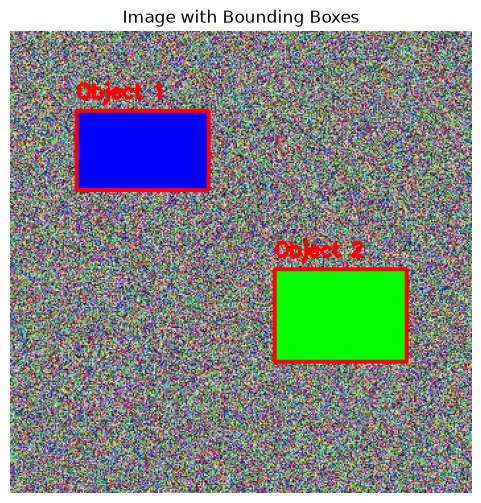

In [10]:
if img_color is not None:
   
    annotated = img_color.copy()
    
    boxes = [(50, 60, 150, 120), (200, 180, 300, 250)]
    labels = ["Object 1", "Object 2"]
    
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        # Draw bounding box 
        cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 0, 255), 2)
        
        # Add label
        cv2.putText(annotated, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
        
    plt.figure(figsize=(6, 6))
    plt.title("Image with Bounding Boxes")
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()


3. Create a blank image of size 500x500 pixels and perform the following operations:
(a) draw a red rectangle (Without infill), a green circle (with infill), and a blue diagonal line on it.
(b) Add your name as a watermark in the bottom-right corner.
(c) Save the image and display it.

[[[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 ...

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]]


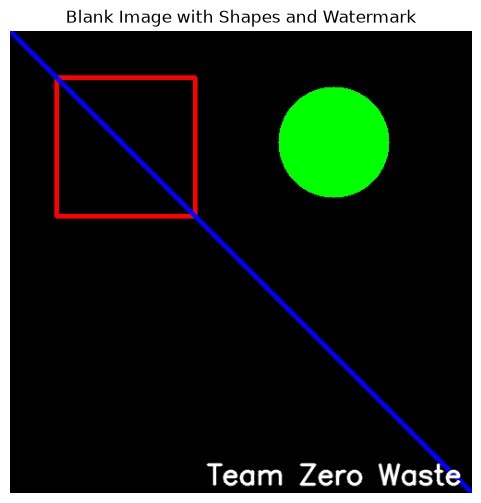

In [11]:
# Blank 500x500 image 
blank_500 = np.zeros((500, 500, 3), dtype=np.uint8)
print(blank_500)

# Red rectangle 
cv2.rectangle(blank_500, (50, 50), (200, 200), (0, 0, 255), 3)

# Green circle (with infill)
cv2.circle(blank_500, (350, 120), 60, (0, 255, 0), -1)

# Blue diagonal line
cv2.line(blank_500, (0, 0), (500, 500), (255, 0, 0), 4)

# Adding watermark bottom-right
watermark_text = "Team Zero Waste"
font = cv2.FONT_HERSHEY_SIMPLEX
text_size = cv2.getTextSize(watermark_text, font, 1, 2)[0]
text_x = 500 - text_size[0] - 10
text_y = 500 - 10
cv2.putText(blank_500, watermark_text, (text_x, text_y), font, 1, (255, 255, 255), 2, cv2.LINE_AA)

# (c) Save and display
cv2.imwrite("watermarked_image.jpg", blank_500)

plt.figure(figsize=(6, 6))
plt.title("Blank Image with Shapes and Watermark")
plt.imshow(cv2.cvtColor(blank_500, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


### Problem 5
1. Read a colored image and convert it to HSV Color Channel image.
(a) Split the HSV image into its three channels: Hue, Saturation, Value.
(b) Display all three channels separately, i.e, 3 separate images displaying 1 channel at a time.

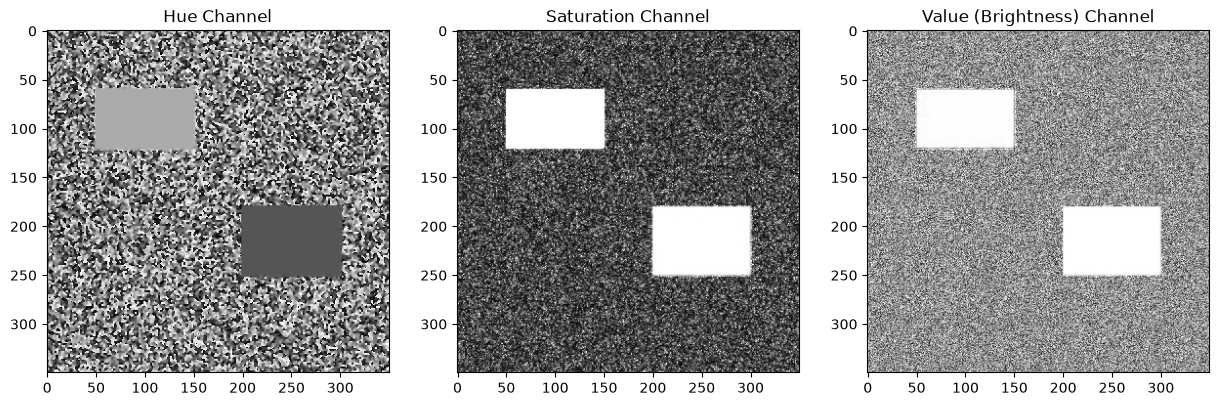

In [12]:
img_color = cv2.imread('dummy_color.jpg')

if img_color is not None:
    # Convert to HSV
    hsv = cv2.cvtColor(img_color, cv2.COLOR_BGR2HSV)
    
    # Split channels
    h, s, v = cv2.split(hsv)
    
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.title("Hue Channel")
    plt.imshow(h, cmap='gray')
    
    plt.subplot(1, 3, 2)
    plt.title("Saturation Channel")
    plt.imshow(s, cmap='gray')

    plt.subplot(1, 3, 3)
    plt.title("Value (Brightness) Channel")
    plt.imshow(v, cmap='gray')
    
    plt.show()


2. Load a color image and convert it from BGR to HSV. Convert the HSV image back to BGR and display all three images: Original BGR, HSV, and Reconverted BGR. (Observe whether the reconverted BGR image looks similar to the original image or not.

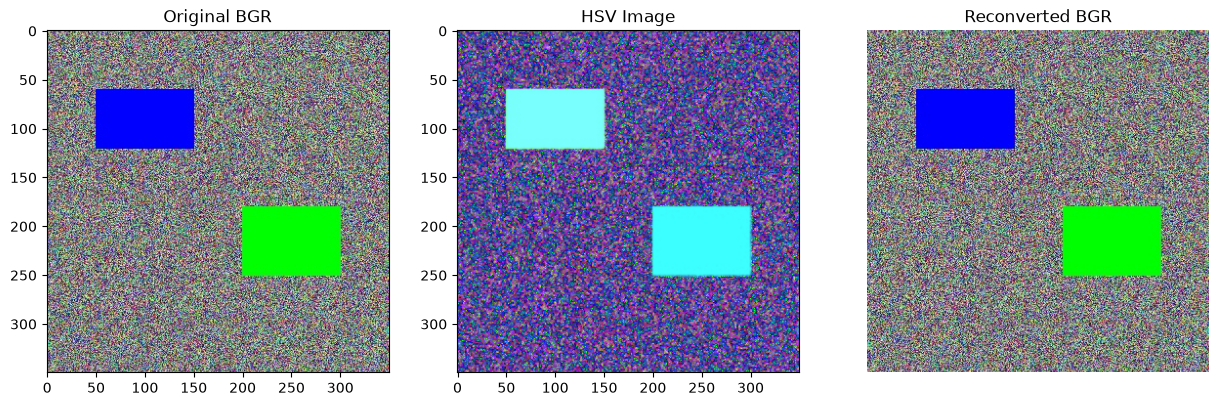

In [13]:
if img_color is not None:
    # Convert to HSV
    hsv_image = cv2.cvtColor(img_color, cv2.COLOR_BGR2HSV)
    
    # Convert back to BGR
    reconverted_bgr = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2BGR)
    
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.title("Original BGR")
    plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))

    plt.subplot(1, 3, 2)
    plt.title("HSV Image")
    plt.imshow(hsv_image)
 
    plt.subplot(1, 3, 3)
    plt.title("Reconverted BGR")
    plt.imshow(cv2.cvtColor(reconverted_bgr, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    
    plt.show()
    


**Observation**: The reconverted BGR image looks identical to the original BGR image since conversion between BGR and HSV is mostly lossless (aside from minor rounding)